# Temporal Markov attribution on GA4 ecommerce journeys

Weekly epoch-by-epoch Markov attribution over the GA4 extract, plus the
data-driven epoch recommendation workflow.

In [1]:
# In Colab, install the package first:
# %pip install "do-attribution[viz,temporal]"
%matplotlib inline
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="Sum of Shapley values")
warnings.filterwarnings("ignore", message="Total removal effect is 0")
pd.set_option("display.width", 160)

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

## Load, summarize, and parse the timestamp column

`anchor_timestamp` gives every journey exactly one anchor. The temporal
classes assign each complete journey to one epoch by that anchor and run an
independent static fit inside every epoch — no smoothing, no state shared
across boundaries. The GA4 sample covers November 2020 through January 2021, providing
daily timestamps for calendar-based and data-driven epoch analysis.

In [2]:
journeys = pd.read_csv("ga4_attribution_journeys.csv")

required = {"path", "conversion", "anchor_timestamp"}
assert required.issubset(journeys.columns), f"missing columns: {required - set(journeys.columns)}"
assert journeys["path"].notna().all() and (journeys["path"].str.len() > 0).all()
assert journeys["conversion"].isin([0, 1]).all()

paths = journeys["path"]
conversions = journeys["conversion"]
timestamps = pd.to_datetime(journeys["anchor_timestamp"]).dt.tz_localize(None)

channels = sorted({channel for path in paths for channel in path.split(" > ")})
path_lengths = paths.str.count(" > ") + 1
print(f"journeys        : {len(journeys):,}")
print(f"conversions     : {conversions.sum():,}  (rate {conversions.mean():.4f})")
print(f"date range      : {timestamps.min().date()} to {timestamps.max().date()}")
print(f"channels ({len(channels)})    : {', '.join(channels)}")
print(f"path length     : mean {path_lengths.mean():.2f}, max {path_lengths.max()}; "
      f"{(path_lengths > 1).mean():.1%} of journeys are multi-touch")
journeys.head()

journeys        : 272,792
conversions     : 4,848  (rate 0.0178)
date range      : 2020-11-01 to 2021-01-31
channels (8)    : Affiliate, Direct, Email, Organic Search, Organic Social, Other, Paid Search, Referral
path length     : mean 1.17, max 12; 11.4% of journeys are multi-touch


,journey_id,path,conversion,journey_start,anchor_timestamp,session_count,touch_count,purchase_count
0,journey_0000001,Organic Search,0,2020-12-12T04:11:17Z,2020-12-12T04:11:17Z,1,1,0
1,journey_0000002,Direct,0,2021-01-07T18:35:34Z,2021-01-07T18:35:34Z,1,1,0
2,journey_0000003,Direct,0,2021-01-20T11:04:59Z,2021-01-20T11:04:59Z,1,1,0
3,journey_0000004,Other > Referral,0,2020-11-04T09:21:11Z,2020-11-04T13:43:30Z,2,2,0
4,journey_0000005,Organic Search,0,2020-12-11T17:25:12Z,2020-12-11T17:25:12Z,1,1,0


## Fit calendar-based weekly epochs

In [3]:
from do_attribution import TemporalMarkovAttribution

temporal_markov = TemporalMarkovAttribution(
    freq="W",
    min_samples_per_epoch=30,
    order=1,
    removal_strategy="redirect_to_null",
)
temporal_markov.fit(paths, timestamps, conversions)
print(f"epochs fitted: {len(temporal_markov.epochs)} "
      f"({temporal_markov.epochs[0]} ... {temporal_markov.epochs[-1]})")
assigned = int(temporal_markov.get_epoch_summary()["n_paths"].sum())
print(f"journeys assigned to an epoch: {assigned:,} of {len(paths):,}")

epochs fitted: 14 (2020-10-26/2020-11-01 ... 2021-01-25/2021-01-31)


journeys assigned to an epoch: 272,792 of 272,792


## Epoch attribution results

In [4]:
attribution_matrix = temporal_markov.get_attribution_matrix()
display(attribution_matrix.round(4))

,Affiliate,Direct,Email,Organic Search,Organic Social,Other,Paid Search,Referral
2020-10-26/2020-11-01,0.0008,0.0903,NaN,0.3840,NaN,0.0896,0.0022,0.4332
2020-11-02/2020-11-08,0.0016,0.1096,0.0000,0.3531,0.0004,0.0947,0.0126,0.4280
2020-11-09/2020-11-15,0.0035,0.0930,NaN,0.3823,0.0005,0.0745,0.0117,0.4345
2020-11-16/2020-11-22,0.0018,0.0978,NaN,0.4076,0.0027,0.0580,0.0132,0.4190
2020-11-23/2020-11-29,0.0007,0.1119,0.0095,0.3693,0.0002,0.0800,0.0112,0.4172
2020-11-30/2020-12-06,0.0016,0.1045,0.0071,0.3710,0.0004,0.0844,0.0168,0.4142
2020-12-07/2020-12-13,0.0011,0.1096,0.0046,0.3525,0.0023,0.0837,0.0166,0.4295
2020-12-14/2020-12-20,0.0011,0.1224,0.0074,0.3578,0.0022,0.0933,0.0183,0.3974
2020-12-21/2020-12-27,0.0009,0.1168,0.0003,0.3261,0.0004,0.0845,0.0101,0.4609
2020-12-28/2021-01-03,0.0075,0.1046,0.0001,0.3629,0.0005,0.0867,0.0236,0.4140


## Epoch summaries and sample-size diagnostics

In [5]:
display(temporal_markov.get_epoch_summary())
thin_cells = temporal_markov.get_channel_epoch_sample_sizes()
print(f"channel-by-epoch cells flagged thin: {int(thin_cells['thin'].sum())} of {len(thin_cells)}")
display(thin_cells[thin_cells["thin"]].head(8))

,n_paths,n_conversions,n_channels,total_removal_effect,base_conversion_probability,effective_min_samples,sufficient_data,fit_ok,n_thin_channels
epoch,,,,,,,,,
2020-10-26/2020-11-01,2033,13,6,1.076062,0.006394,30,True,True,1
2020-11-02/2020-11-08,17286,249,8,1.154013,0.014405,30,True,True,1
2020-11-09/2020-11-15,15224,341,7,1.200732,0.022399,30,True,True,0
2020-11-16/2020-11-22,17511,374,7,1.229428,0.021358,30,True,True,0
2020-11-23/2020-11-29,19910,515,8,1.223984,0.025866,30,True,True,0
2020-11-30/2020-12-06,22140,590,8,1.246295,0.026649,30,True,True,0
2020-12-07/2020-12-13,29413,772,8,1.238572,0.026247,30,True,True,0
2020-12-14/2020-12-20,25708,549,8,1.259294,0.021355,30,True,True,0
2020-12-21/2020-12-27,17947,233,8,1.223624,0.012983,30,True,True,1


channel-by-epoch cells flagged thin: 7 of 107


n_paths_containing_channel  n_conversions_on_paths_containing_channel  thin
channel        epoch                                                                                             
Affiliate      2020-10-26/2020-11-01                           1                                          0  True
Email          2020-11-02/2020-11-08                           2                                          0  True
               2020-12-21/2020-12-27                           4                                          2  True
               2020-12-28/2021-01-03                           1                                          0  True
               2021-01-04/2021-01-10                           1                                          0  True
Organic Social 2021-01-11/2021-01-17                           7                                          0  True
Email          2021-01-18/2021-01-24                           2                                          0  True

## Temporal model summary (plain-text report)

In [6]:
print(temporal_markov.summary())

Temporal Attribution Summary
Model: TemporalMarkovAttribution
Epoch source: calendar:W
Timeline: 2020-10-26 to 2021-02-01
Boundaries: 2020-10-26 | 2020-11-02 | 2020-11-09 | 2020-11-16 | 2020-11-23 | 2020-11-30 | 2020-12-07 | 2020-12-14 | 2020-12-21 | 2020-12-28 | 2021-01-04 | 2021-01-11 | 2021-01-18 | 2021-01-25 | 2021-02-01
Sample floor: 30 paths
Overall: 272792 paths, 4848 conversions, 1.78% conversion rate

Epochs
+-----------------------+------------+------------+-------+-------------+---------+--------+-------------------------------------------------------+
| Epoch                 | Start      | End        | Paths | Conversions | Conv. % | Health | Top channels                                          |
+-----------------------+------------+------------+-------+-------------+---------+--------+-------------------------------------------------------+
| 2020-10-26/2020-11-01 | 2020-10-26 | 2020-11-02 | 2033  | 13          | 0.64%   | PASS   | Referral 43.32%, Organic Search 38.40%,

## Flat DataFrame export

`to_dataframes()` returns flat, string-keyed tables ready for Parquet or
SQL — attribution, raw removal effects, the conversion-probability trend,
retained transition matrices, and the sample diagnostics.

In [7]:
tables = temporal_markov.to_dataframes()
print("keys:", list(tables))
display(tables["attribution"].head(10))
display(tables["conversion_probability"])

keys: ['attribution', 'removal_effects', 'conversion_probability', 'transition_matrices', 'epoch_summary', 'channel_epoch_sample_sizes']


,epoch,channel,attribution
0,2020-10-26/2020-11-01,Affiliate,0.000756
1,2020-10-26/2020-11-01,Direct,0.090319
2,2020-10-26/2020-11-01,Email,NaN
3,2020-10-26/2020-11-01,Organic Search,0.383951
4,2020-10-26/2020-11-01,Organic Social,NaN
5,2020-10-26/2020-11-01,Other,0.089560
6,2020-10-26/2020-11-01,Paid Search,0.002218
7,2020-10-26/2020-11-01,Referral,0.433196
8,2020-11-02/2020-11-08,Affiliate,0.001582
9,2020-11-02/2020-11-08,Direct,0.109574


,epoch,conversion_probability
0,2020-10-26/2020-11-01,0.006394
1,2020-11-02/2020-11-08,0.014405
2,2020-11-09/2020-11-15,0.022399
3,2020-11-16/2020-11-22,0.021358
4,2020-11-23/2020-11-29,0.025866
5,2020-11-30/2020-12-06,0.026649
6,2020-12-07/2020-12-13,0.026247
7,2020-12-14/2020-12-20,0.021355
8,2020-12-21/2020-12-27,0.012983
9,2020-12-28/2021-01-03,0.008102


## Weekly attribution trends

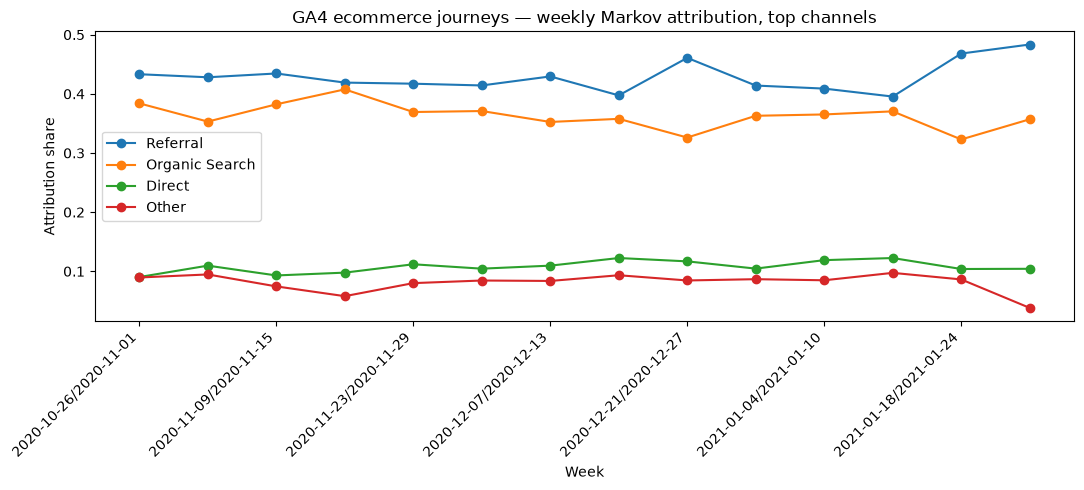

In [8]:
top_channels = attribution_matrix.mean().sort_values(ascending=False).head(4).index
trend_frame = attribution_matrix[top_channels]
trend_frame.index = [str(epoch) for epoch in trend_frame.index]
ax = trend_frame.plot(marker="o", figsize=(11, 5))
ax.set_title("GA4 ecommerce journeys — weekly Markov attribution, top channels")
ax.set_ylabel("Attribution share")
ax.set_xlabel("Week")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.gcf().savefig(IMAGES / "ga4_temporal_markov.png", dpi=110, bbox_inches="tight")
plt.show()

## Data-driven epoch recommendation

`fit_recommended` segments the global daily conversion-rate signal with a
penalized piecewise-affine detector, enforces width and sample floors, and
dispatches one independent Markov fit per recommended epoch.

In [9]:
recommended_markov = TemporalMarkovAttribution(
    order=1,
    removal_strategy="redirect_to_null",
    min_samples_per_epoch=30,
)
recommended_markov.fit_recommended(paths, conversions, timestamps)
recommendation = recommended_markov.epoch_recommendation
print("recommended boundaries:", [str(b.date()) for b in recommendation.boundaries])
print(recommended_markov.summary())

recommended boundaries: ['2020-11-01', '2020-11-15', '2020-12-12', '2020-12-30', '2021-02-01']
Temporal Attribution Summary
Model: TemporalMarkovAttribution
Epoch source: recommended:conversion_rate
Timeline: 2020-11-01 to 2021-02-01
Boundaries: 2020-11-01 | 2020-11-15 | 2020-12-12 | 2020-12-30 | 2021-02-01
Sample floor: 30 paths
Overall: 272792 paths, 4848 conversions, 1.78% conversion rate

Epochs
+-------+------------+------------+--------+-------------+---------+--------+-------------------------------------------------------+
| Epoch | Start      | End        | Paths  | Conversions | Conv. % | Health | Top channels                                          |
+-------+------------+------------+--------+-------------+---------+--------+-------------------------------------------------------+
| E1    | 2020-11-01 | 2020-11-15 | 32926  | 580         | 1.76%   | PASS   | Referral 43.32%, Organic Search 36.99%, Direct 9.99%  |
| E2    | 2020-11-15 | 2020-12-12 | 84231  | 2111        | 2.

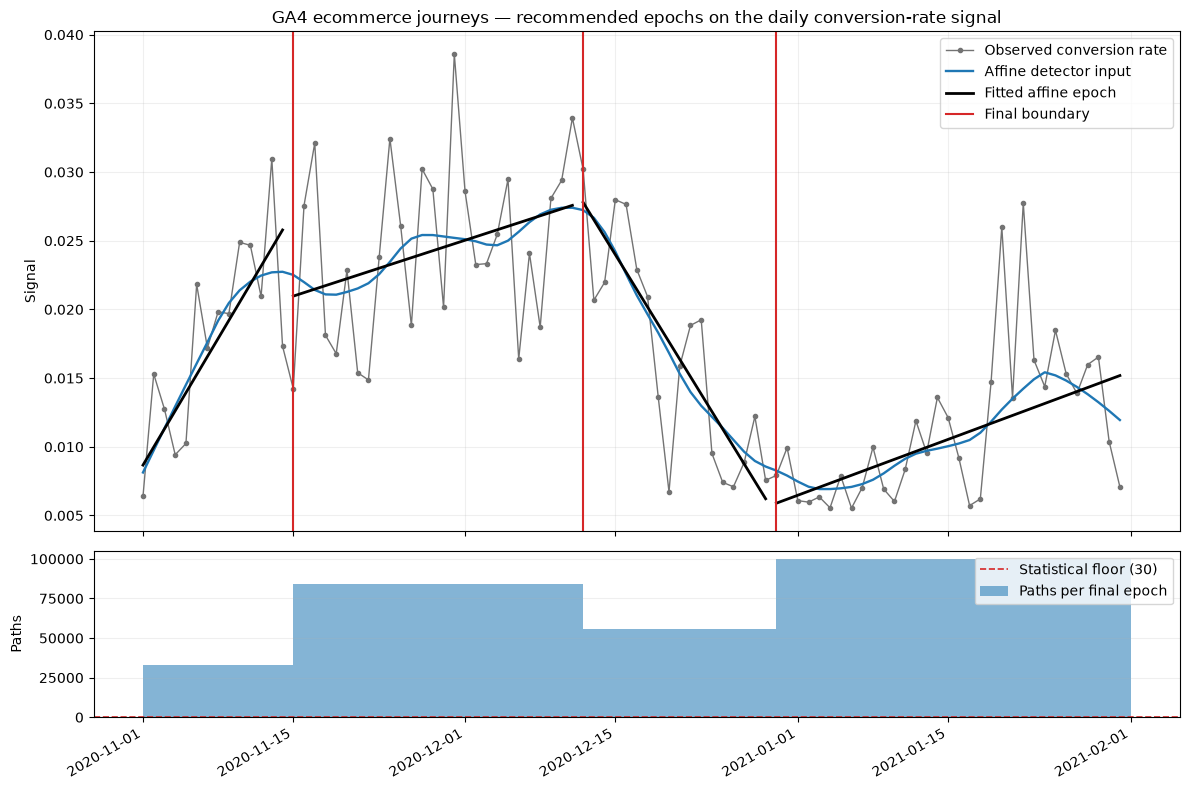

In [10]:
from do_attribution.visualization import plot_epoch_recommendation

fig = plot_epoch_recommendation(
    recommendation,
    title="GA4 ecommerce journeys — recommended epochs on the daily conversion-rate signal",
)
fig.savefig(IMAGES / "ga4_markov_epoch_recommendation.png", dpi=110, bbox_inches="tight")
plt.show()